# Triplet Extraction & Knowledge Graph Construction


## 1. Load propositions

Load the source propositions from `data/propositions.json`. Each entry is a short factual statement that will later be converted into knowledge graph triplets.

In [ ]:
from pathlib import Path
import json

directory = Path.cwd().parent


Current working directory: /Users/fserracrespi/Desktop/historically-disputed-events-online-encyclopedias 3


In [9]:


with open(directory/"data/propositions.json", "r", encoding="utf-8") as f:
    propositions_dict = json.load(f)

print(propositions_dict)

{'proposition_0': 'The Falkland Islands are an archipelago in the South Atlantic Ocean.', 'proposition_1': 'The Falkland Islands are located on the Patagonian Shelf.', 'proposition_2': 'The Falkland Islands are commonly referred to as the Falklands.', 'proposition_3': 'The Falkland Islands are also known as the Islas Malvinas.', 'proposition_4': 'The Falkland Islands are a British Overseas Territory.', 'proposition_5': 'The Falkland Islands have internal self-governance as a British Overseas Territory.', 'proposition_6': "The United Kingdom takes responsibility for the Falkland Islands' defence and foreign affairs.", 'proposition_7': 'The capital of the Falkland Islands is Stanley on East Falkland.', 'proposition_8': 'The largest settlement in the Falkland Islands is Stanley on East Falkland.'}


## 2. Load the local LLM and define the triplet extractor

Load a local Qwen3-8B model via `llama-cpp-python` and define `extract_triplets`, which prompts the model to extract `(subject, relation, object)` triplets from a single proposition.

- The model is constrained to a JSON schema so its output is always a list of triplets.
- Subjects, relations, and objects are normalized to `snake_case`, with determiners/articles removed.
- The system prompt instructs the model to extract only explicitly stated facts (no inference or invention).

In [15]:
from llama_cpp import Llama
import json


llm = Llama(
    model_path="/Users/fserracrespi/Desktop/historically-disputed-events-online-encyclopedias 3/models/Qwen3-8B-Q4_K_M.gguf",
    n_ctx=4096,
    n_gpu_layers=-1,
    verbose=False
)


def extract_triplets(proposition):

    schema = {
        "type": "object",
        "properties": {
            "triplets": {
                "type": "array",
                "items": {
                    "type": "object",
                    "properties": {
                        "subject": {"type": "string"},
                        "relation": {"type": "string"},
                        "object": {"type": "string"}
                    },
                    "required": [
                        "subject",
                        "relation",
                        "object"
                    ],
                    "additionalProperties": False
                }
            }
        },
        "required": ["triplets"],
        "additionalProperties": False
    }

    messages = [
        {
            "role": "system",
            "content": (
                "You are a knowledge graph extraction system. "
                "Extract only explicitly stated factual information. "
                "Remove determiners/articles from subjects and objects "
                "(e.g. the, a, an). "
                "Do not invent information."
            )
        },
        {
            "role": "user",
            "content": f"""
    Extract all factual knowledge graph triples from:

    {proposition}
    """
        }
    ]

    response = llm.create_chat_completion(
        messages=messages,
        temperature=0,
        max_tokens=256,
        response_format={
            "type": "json_object",
            "schema": schema
        }
    )

    result = response["choices"][0]["message"]["content"]

    data = json.loads(result)

    return data["triplets"]

## 3. Run extraction over all propositions

Iterate over every proposition, extract its triplets, and collect them into `triplets_list`.


In [18]:
triplets_list = []
for preposition_key in propositions_dict:
    proposition = propositions_dict[preposition_key]
    print(proposition)
    triplets = extract_triplets(proposition)[0]
    print(triplets)

The Falkland Islands are an archipelago in the South Atlantic Ocean.
{'subject': 'Falkland Islands', 'relation': 'are', 'object': 'archipelago'}
The Falkland Islands are located on the Patagonian Shelf.
{'subject': 'Falkland Islands', 'relation': 'located on', 'object': 'Patagonian Shelf'}
The Falkland Islands are commonly referred to as the Falklands.
{'subject': 'Falkland Islands', 'relation': 'commonly referred to as', 'object': 'Falklands'}
The Falkland Islands are also known as the Islas Malvinas.
{'subject': 'Falkland Islands', 'relation': 'also known as', 'object': 'Islas Malvinas'}
The Falkland Islands are a British Overseas Territory.
{'subject': 'Falkland Islands', 'relation': 'is', 'object': 'British Overseas Territory'}
The Falkland Islands have internal self-governance as a British Overseas Territory.
{'subject': 'Falkland Islands', 'relation': 'have', 'object': 'internal self-governance'}
The United Kingdom takes responsibility for the Falkland Islands' defence and foreig

In [3]:
triplets_list = []
for preposition_key in propositions_dict:
    proposition = propositions_dict[preposition_key]
    triplets = extract_triplets(proposition)
    if len(triplets) > 1:
        for triplet in triplets:
            triplets_list.append({
                "proposition": proposition,
                "triplets": [triplet]
            })
    else:
        triplets_list.append({
            "proposition": proposition,
            "triplets": triplets
        })

    print(f"Proposition: {proposition}")
    print(f"Triplets: {triplets}")
    print("-" * 40)

print(f"Total triplets extracted: {len(triplets_list)}")

Proposition: The Falkland Islands are an archipelago in the South Atlantic Ocean.
Triplets: [{'subject': 'Falkland Islands', 'relation': 'are', 'object': 'archipelago'}, {'subject': 'Falkland Islands', 'relation': 'located in', 'object': 'South Atlantic Ocean'}]
----------------------------------------
Proposition: The Falkland Islands are located on the Patagonian Shelf.
Triplets: [{'subject': 'Falkland Islands', 'relation': 'located on', 'object': 'Patagonian Shelf'}]
----------------------------------------
Proposition: The Falkland Islands are commonly referred to as the Falklands.
Triplets: [{'subject': 'Falkland Islands', 'relation': 'commonly referred to as', 'object': 'Falklands'}]
----------------------------------------
Proposition: The Falkland Islands are also known as the Islas Malvinas.
Triplets: [{'subject': 'Falkland Islands', 'relation': 'also known as', 'object': 'Islas Malvinas'}]
----------------------------------------
Proposition: The Falkland Islands are a Britis

## 4. Build the knowledge graph

Define helper functions to turn the extracted triplets into a `networkx` directed multigraph and to visualize it.

- `create_knowledge_graph`: adds each triplet's subject and object as nodes, and adds a directed edge (subject → object) carrying the `relation` and source `proposition` as edge attributes.
- `plot_knowledge_graph`: lays out the graph with a spring layout and draws nodes, edges, and relation labels using `matplotlib`.

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

def create_knowledge_graph(data):
    """
    Creates a directed knowledge graph from extracted triplets.

    Nodes:
        - subject
        - object

    Edges:
        - relation

    Edge attributes:
        - We can define additional attributes as needed, such Q-IDS or other identifiers.
    """

    graph = nx.MultiDiGraph()

    for item in data:
        proposition = item["proposition"]

        for triplet in item["triplets"]:

            subject = triplet["subject"]
            relation = triplet["relation"]
            object_ = triplet["object"]

            # Add nodes
            graph.add_node(subject)
            graph.add_node(object_)

            # Add directed edge: subject -> object
            graph.add_edge(
                subject,
                object_,
                relation=relation)

    return graph


def plot_knowledge_graph(graph):
    plt.figure(figsize=(16, 10))

    pos = nx.spring_layout(
        graph,
        seed=42,
        k=1.5
    )

    nx.draw_networkx_nodes(
        graph,
        pos,
        node_size=2500
    )

    nx.draw_networkx_labels(
        graph,
        pos,
        font_size=8
    )

    nx.draw_networkx_edges(
        graph,
        pos,
        arrows=True,
        arrowsize=20
    )

    edge_labels = {
        (u, v): data["relation"]
        for u, v, data in graph.edges(data=True)
    }

    nx.draw_networkx_edge_labels(
        graph,
        pos,
        edge_labels=edge_labels,
        font_size=7
    )

    plt.axis("off")
    plt.show()


## 5. Build and visualize the graph

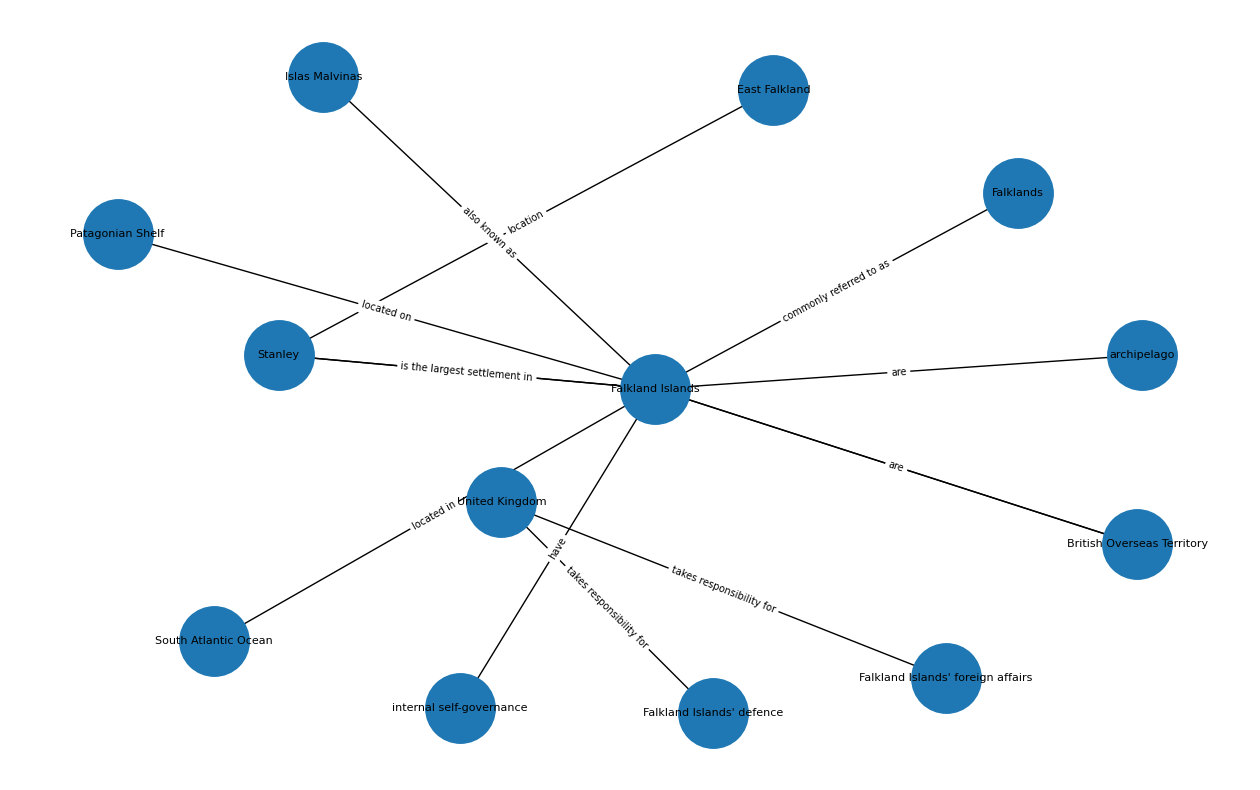

In [5]:
G = create_knowledge_graph(triplets_list)

plot_knowledge_graph(G)